# IBM AML (HI-Small): history features + edge-aware Graph Neural Network
**Task:** edge classification. Accounts are nodes, transactions are directed edges, and the label is `Is Laundering`.

**Why the first GNN notebook scored ~0.001 PR-AUC (this is *not* leakage).** 0.1% of transactions are laundering, so a PR-AUC of ~0.001 is exactly what a random scorer gets. Leakage would inflate the score, not flatten it. The real causes were:
1. **Only one gradient step per epoch** (full-batch), so 40 epochs = 40 updates. The loss was still falling when training stopped.
2. **No account history in the edge features.** In the reference notebook, trees on the 9 basic columns reach only PR-AUC ≈ 0.12. Adding 20 *backward-looking* account-history features lifts it to ≈ 0.62 and F1 to ≈ 66.

**What this notebook does (replicating the reference recipe, but with a GNN as the model)**
- Computes the same 20 causal account-history features (each uses only earlier rows).
- Feeds them as **edge features** into a GNN with **edge updates** (GINE layers plus an edge-update MLP per layer, the design behind the strongest GNN baseline in the IBM paper).
- Trains with **many mini-batch steps per epoch**: time-contiguous sub-graphs ("chunks") of ~150k transactions, so it needs no neighbour-sampling libraries and fits in Codespaces RAM.
- Uses a chronological 60/20/20 split and picks the decision threshold on validation only.
- Optionally runs a gradient-boosted-tree baseline on the same features and the reference notebook's *retroactive flagging* post-processing.

## 1. Setup

In [2]:
%pip install -q torch torch_geometric kaggle pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, time, subprocess, gc, numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch_geometric.nn import GINEConv
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report, precision_recall_curve)

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# ---- Config ----
MAX_EDGES = None          # None = all 5.08M HI-Small transactions. Use e.g. 2_000_000 if RAM is tight (<8 GB).
CHUNK     = 150_000       # transactions per training sub-graph
HIDDEN, LAYERS, DROPOUT = 64, 2, 0.1
EPOCHS, LR, PATIENCE    = 30, 2e-3, 8
RUN_TREE_BASELINE = True  # ~2 min, gives a reference point on identical features

In C:\Users\imroo\Downloads\anaconda\Lib\site-packages\matplotlib\mpl-data\stylelib\bmh.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In C:\Users\imroo\Downloads\anaconda\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In C:\Users\imroo\Downloads\anaconda\Lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test_patch.mplstyle: The text.kerning_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.


device: cpu


## 2. Get the data
Uses your `/kaggle/input/...` path if it exists; otherwise downloads with the Kaggle API (set Codespaces secrets `KAGGLE_USERNAME` and `KAGGLE_KEY`, or put `kaggle.json` in `~/.kaggle/`).

In [4]:
KAGGLE_PATH = '/kaggle/input/ibm-transactions-for-anti-money-laundering-aml/HI-Small_Trans.csv'
LOCAL_PATH  = 'data/HI-Small_Trans.csv'
if os.path.exists(KAGGLE_PATH):
    DATA_PATH = KAGGLE_PATH
else:
    DATA_PATH = LOCAL_PATH
    if not os.path.exists(LOCAL_PATH):
        os.makedirs('data', exist_ok=True)
        subprocess.run(['kaggle','datasets','download','-d','ealtman2019/ibm-transactions-for-anti-money-laundering-aml',
                        '-f','HI-Small_Trans.csv','-p','data','--unzip'], check=True)
        if os.path.exists('data/HI-Small_Trans.csv.zip'):
            import zipfile; zipfile.ZipFile('data/HI-Small_Trans.csv.zip').extractall('data')
print("Using:", DATA_PATH)

Using: data/HI-Small_Trans.csv


## 3. Causal account-history features
Every feature looks only **backwards** in time (rows earlier in the time-sorted file): has the sender paid this beneficiary before, how fast is the sender adding new payees, how busy is the receiver, and so on. Feature definitions follow the reference notebook (Altman et al. data; "NoGNN" recipe).

In [5]:
COLS = ["ts","from_bank","from_acct","to_bank","to_acct","amt_recv","cur_recv","amt_paid","cur_paid","fmt","label"]
FEATURE_WINDOWS = {"1h": 3600, "24h": 86400, "7d": 7*86400}

def _window_counts(group_codes, secs, flag, window):
    order = np.lexsort((secs, group_codes))
    key = group_codes[order].astype(np.int64) * 10**8 + secs[order]
    prefix = np.concatenate([[0], np.cumsum(flag[order])])
    idx = np.arange(len(key))
    left = np.searchsorted(key, key - window, side="left")
    out = np.empty(len(key), dtype=np.int64)
    out[order] = prefix[idx] - prefix[left]
    return out

def add_features(tx):
    df = tx.copy()
    secs = ((df.ts - df.ts.min()).dt.total_seconds()).to_numpy(np.int64)
    sender = pd.factorize(df.from_acct)[0]; recv = pd.factorize(df.to_acct)[0]
    pair = df.groupby(["from_acct","to_acct"], sort=False)
    df["pair_prev_cnt"] = pair.cumcount()
    df["is_first_pair"] = (df.pair_prev_cnt == 0).astype(np.int8)
    df["pair_age_days"] = (df.ts - pair.ts.transform("min")).dt.total_seconds() / 86400
    df["hrs_since_last_pair"] = pair.ts.diff().dt.total_seconds() / 3600
    s = df.groupby("from_acct", sort=False)
    df["sender_prev_cnt"] = s.cumcount()
    df["sender_age_days"] = (df.ts - s.ts.transform("min")).dt.total_seconds() / 86400
    df["hrs_since_last_sender_tx"] = s.ts.diff().dt.total_seconds() / 3600
    df["sender_prev_partners"] = s.is_first_pair.cumsum() - df.is_first_pair
    r = df.groupby("to_acct", sort=False)
    df["recv_prev_cnt"] = r.cumcount()
    df["recv_age_days"] = (df.ts - r.ts.transform("min")).dt.total_seconds() / 86400
    ones = np.ones(len(df), dtype=np.int64); first = df.is_first_pair.to_numpy(np.int64)
    for name, w in FEATURE_WINDOWS.items():
        df[f"sender_tx_{name}"]      = _window_counts(sender, secs, ones,  w)
        df[f"sender_new_ben_{name}"] = _window_counts(sender, secs, first, w)
        df[f"recv_tx_{name}"]        = _window_counts(recv,   secs, ones,  w)
    df["new_ben_share_24h"] = df.sender_new_ben_24h / df.sender_tx_24h.clip(lower=1)
    return df

NEW_FEATURES = ["is_first_pair","pair_prev_cnt","pair_age_days","hrs_since_last_pair","sender_prev_cnt","sender_age_days",
                "hrs_since_last_sender_tx","sender_prev_partners","recv_prev_cnt","recv_age_days","new_ben_share_24h"] + \
               [f"{p}_{n}" for n in FEATURE_WINDOWS for p in ("sender_tx","sender_new_ben","recv_tx")]
BASIC = ["hour","dow","log_amt_paid","cur_recv","cur_paid","fmt","cross_cur","cross_bank","self_xfer"]

t0 = time.time()
tx = pd.read_csv(DATA_PATH, header=0, names=COLS, parse_dates=["ts"], dtype={"from_bank": str, "to_bank": str})
tx = tx.sort_values("ts", kind="stable").reset_index(drop=True)
if MAX_EDGES: tx = tx.iloc[:MAX_EDGES].reset_index(drop=True)
print(f"{len(tx):,} transactions, {tx.label.sum():,} laundering ({tx.label.mean():.3%})")

df = add_features(tx)
df["hour"], df["dow"] = df.ts.dt.hour, df.ts.dt.dayofweek
df["log_amt_paid"] = np.log1p(df.amt_paid)
df["cross_cur"]  = (df.cur_recv != df.cur_paid).astype(np.int8)
df["cross_bank"] = (df.from_bank != df.to_bank).astype(np.int8)
df["self_xfer"]  = (df.from_acct == df.to_acct).astype(np.int8)
n = len(df); n_tr, n_va = int(.6*n), int(.8*n)
print(f"features built in {time.time()-t0:.0f}s | split sizes: {n_tr:,} / {n_va-n_tr:,} / {n-n_va:,}")
print("laundering in train/val/test:", int(df.label[:n_tr].sum()), int(df.label[n_tr:n_va].sum()), int(df.label[n_va:].sum()))

5,078,345 transactions, 5,177 laundering (0.102%)


C:\Users\imroo\AppData\Local\Temp\ipykernel_28016\2719841263.py:51: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["hour"], df["dow"] = df.ts.dt.hour, df.ts.dt.dayofweek


features built in 72s | split sizes: 3,047,007 / 1,015,669 / 1,015,669
laundering in train/val/test: 2298 1082 1797


## 4. (Optional) Tree baseline on the same features
A sanity check: the reference notebook reports test F1 ≈ 66 here. It also confirms the features and split are sound.

In [6]:
def best_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    return th[(2*pr*rc / np.clip(pr+rc, 1e-12, None))[:-1].argmax()]

def report(y, p, thr):
    pred = (p >= thr).astype(int)
    return dict(Accuracy=accuracy_score(y, pred), Precision=precision_score(y, pred, zero_division=0),
                Recall=recall_score(y, pred, zero_division=0), F1=f1_score(y, pred, zero_division=0),
                ROC_AUC=roc_auc_score(y, p), PR_AUC=average_precision_score(y, p))

results = {}
if RUN_TREE_BASELINE:
    Xt = df[BASIC + NEW_FEATURES].copy()
    for c in ["cur_recv","cur_paid","fmt"]: Xt[c] = Xt[c].astype("category")
    y_all = df.label.to_numpy()
    gb = HistGradientBoostingClassifier(max_iter=300, class_weight="balanced", categorical_features="from_dtype",
                                        early_stopping=True, validation_fraction=0.1, random_state=0).fit(Xt.iloc[:n_tr], y_all[:n_tr])
    pv_gb, pt_gb = gb.predict_proba(Xt.iloc[n_tr:n_va])[:,1], gb.predict_proba(Xt.iloc[n_va:])[:,1]
    thr_gb = best_threshold(y_all[n_tr:n_va], pv_gb)
    results["Trees (same features)"] = report(y_all[n_va:], pt_gb, thr_gb)
    print(pd.Series(results["Trees (same features)"]).round(4).to_string())
    del Xt, gb; gc.collect()

Accuracy     0.9990
Precision    0.7976
Recall       0.6010
F1           0.6855
ROC_AUC      0.9840
PR_AUC       0.6352


## 5. Edge features and tensors
Counts, ages and gaps are `log1p`-transformed, everything is standardised with **train-only** statistics, and categorical columns (payment format, currencies) are one-hot encoded.

In [7]:
basic_num = pd.DataFrame({"hour": df.hour/23.0, "dow": df.dow/6.0, "log_amt_paid": df.log_amt_paid,
                          "cross_cur": df.cross_cur.astype(float), "cross_bank": df.cross_bank.astype(float), "self_xfer": df.self_xfer.astype(float)})
hist = df[NEW_FEATURES].astype(np.float64)
for c in ["hrs_since_last_pair", "hrs_since_last_sender_tx"]:
    hist[c + "_isna"] = hist[c].isna().astype(float); hist[c] = hist[c].fillna(0)
hist = np.log1p(hist.clip(lower=0))
num = pd.concat([basic_num, hist], axis=1)
mu, sd = num.iloc[:n_tr].mean(), num.iloc[:n_tr].std() + 1e-6
num = ((num - mu) / sd).clip(-5, 5)
cat = pd.get_dummies(df[["fmt","cur_recv","cur_paid"]].astype(str), dtype=float)
EA  = torch.tensor(pd.concat([num, cat], axis=1).to_numpy(np.float32))
Y   = torch.tensor(df.label.to_numpy(), dtype=torch.float)
AMT = torch.tensor(df[["amt_paid","amt_recv"]].to_numpy(np.float32))

codes, _ = pd.factorize(pd.concat([df.from_acct, df.to_acct], ignore_index=True))
SND, RCV = codes[:n].astype(np.int64), codes[n:].astype(np.int64)      # kept for retroactive flagging
EI  = torch.tensor(np.vstack([SND, RCV]))
SECS = ((df.ts - df.ts.min()).dt.total_seconds()).to_numpy(np.int64)
print(f"{codes.max()+1:,} accounts | edge feature dim = {EA.shape[1]}")
del basic_num, hist, num, cat, codes; gc.collect()

515,080 accounts | edge feature dim = 65


0

## 6. Model: edge-aware GNN with edge updates
Per layer: **GINE** message passing (sum of neighbour messages enriched with edge embeddings) on a bidirectional graph, then an **edge-update MLP** `e ← e + MLP([h_src, h_dst, e])`. The classifier reads `[h_src, h_dst, e]` for each transaction.

**Chunking:** each training step uses one time-contiguous slice of `CHUNK` transactions as its own graph (accounts re-indexed locally). Chunk boundaries are randomly shifted every epoch. Node features are label-free structural features (log in/out degree and log amount sent/received inside the chunk).

In [8]:
def make_chunk(lo, hi):
    ei = EI[:, lo:hi]
    nodes, inv = torch.unique(ei, return_inverse=True)
    m = len(nodes)
    out_deg = torch.bincount(inv[0], minlength=m).float(); in_deg = torch.bincount(inv[1], minlength=m).float()
    out_amt = torch.zeros(m).index_add_(0, inv[0], AMT[lo:hi, 0]); in_amt = torch.zeros(m).index_add_(0, inv[1], AMT[lo:hi, 1])
    x = torch.stack([out_deg, in_deg, out_amt, in_amt], 1).log1p()
    x = (x - x.mean(0)) / (x.std(0) + 1e-6)
    return x.to(device), inv.to(device), EA[lo:hi].to(device), Y[lo:hi].to(device)

def mlp(i, h, o): return nn.Sequential(nn.Linear(i, h), nn.ReLU(), nn.Linear(h, o))

class AMLGNN(nn.Module):
    def __init__(self, node_in, edge_in, h=64, layers=2, drop=0.1):
        super().__init__()
        self.node_enc, self.edge_enc = nn.Linear(node_in, h), mlp(edge_in, h, h)
        self.convs = nn.ModuleList(GINEConv(mlp(h, h, h), edge_dim=h) for _ in range(layers))
        self.norms = nn.ModuleList(nn.BatchNorm1d(h) for _ in range(layers))
        self.upd   = nn.ModuleList(mlp(3*h, h, h) for _ in range(layers))
        self.head  = nn.Sequential(nn.Linear(3*h, h), nn.ReLU(), nn.Dropout(drop), nn.Linear(h, 1))
        self.drop = drop

    def forward(self, x, ei, ea):
        h, e = F.relu(self.node_enc(x)), self.edge_enc(ea)
        ei2 = torch.cat([ei, ei.flip(0)], 1)                      # bidirectional message passing
        for conv, nm, upd in zip(self.convs, self.norms, self.upd):
            h = h + F.dropout(F.relu(nm(conv(h, ei2, torch.cat([e, e], 0)))), self.drop, self.training)
            e = e + upd(torch.cat([h[ei[0]], h[ei[1]], e], 1))
        return self.head(torch.cat([h[ei[0]], h[ei[1]], e], 1)).squeeze(-1)

model = AMLGNN(4, EA.shape[1], HIDDEN, LAYERS, DROPOUT).to(device)
print("parameters:", sum(p.numel() for p in model.parameters()))

@torch.no_grad()
def predict(lo, hi):
    model.eval(); out = []
    for a in range(lo, hi, CHUNK):
        x, ei, ea, _ = make_chunk(a, min(a + CHUNK, hi))
        out.append(torch.sigmoid(model(x, ei, ea)).cpu())
    return torch.cat(out).numpy()

parameters: 79361


## 7. Train
Weighted BCE (`pos_weight` = √(neg/pos)), AdamW + cosine schedule, ~20 mini-batch steps per epoch, best epoch chosen by validation PR-AUC.

In [9]:
pos = Y[:n_tr].sum().item(); pos_w = torch.tensor(((n_tr - pos) / pos) ** 0.5, device=device)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-5)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
y_va = Y[n_tr:n_va].numpy()
hist_log, best_ap, best_state, bad = [], -1, None, 0

for ep in range(1, EPOCHS + 1):
    t0 = time.time(); model.train()
    off = np.random.randint(0, CHUNK)
    bounds = sorted(set([0] + list(range(off, n_tr, CHUNK)) + [n_tr]))
    spans = [(a, b) for a, b in zip(bounds[:-1], bounds[1:]) if b - a > 1000]
    np.random.shuffle(spans); losses = []
    for a, b in spans:
        x, ei, ea, y = make_chunk(a, b)
        loss = F.binary_cross_entropy_with_logits(model(x, ei, ea), y, pos_weight=pos_w)
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        losses.append(loss.item())
    sched.step()
    ap = average_precision_score(y_va, predict(n_tr, n_va))
    hist_log.append((np.mean(losses), ap))
    if ap > best_ap: best_ap, best_state, bad = ap, {k: v.detach().clone() for k, v in model.state_dict().items()}, 0
    else: bad += 1
    print(f"epoch {ep:02d} | steps {len(spans)} | loss {np.mean(losses):.4f} | val PR-AUC {ap:.4f} | {time.time()-t0:.0f}s")
    if bad >= PATIENCE: print("early stop"); break

model.load_state_dict(best_state)

epoch 01 | steps 21 | loss 0.3598 | val PR-AUC 0.0183 | 35s
epoch 02 | steps 22 | loss 0.2013 | val PR-AUC 0.0052 | 34s
epoch 03 | steps 21 | loss 0.1060 | val PR-AUC 0.1010 | 38s
epoch 04 | steps 22 | loss 0.0674 | val PR-AUC 0.2300 | 41s
epoch 05 | steps 22 | loss 0.0592 | val PR-AUC 0.3927 | 50s
epoch 06 | steps 21 | loss 0.0548 | val PR-AUC 0.4293 | 47s
epoch 07 | steps 21 | loss 0.0495 | val PR-AUC 0.4781 | 45s
epoch 08 | steps 21 | loss 0.0459 | val PR-AUC 0.5212 | 46s
epoch 09 | steps 21 | loss 0.0458 | val PR-AUC 0.5292 | 45s
epoch 10 | steps 22 | loss 0.0455 | val PR-AUC 0.5439 | 47s
epoch 11 | steps 21 | loss 0.0443 | val PR-AUC 0.5491 | 48s
epoch 12 | steps 21 | loss 0.0435 | val PR-AUC 0.5544 | 50s
epoch 13 | steps 21 | loss 0.0455 | val PR-AUC 0.5505 | 47s
epoch 14 | steps 21 | loss 0.0423 | val PR-AUC 0.5595 | 47s
epoch 15 | steps 21 | loss 0.0408 | val PR-AUC 0.5611 | 46s
epoch 16 | steps 21 | loss 0.0420 | val PR-AUC 0.5623 | 46s
epoch 17 | steps 21 | loss 0.0397 | val 

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\imroo\\Downloads\\anaconda\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\LastResortHE-Regular.ttf'

Error in callback <function _draw_all_if_interactive at 0x0000025D09EED6C0> (for post_execute), with arguments args (),kwargs {}:


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\imroo\\Downloads\\anaconda\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\LastResortHE-Regular.ttf'

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\imroo\\Downloads\\anaconda\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\LastResortHE-Regular.ttf'

<Figure size 1000x300 with 2 Axes>

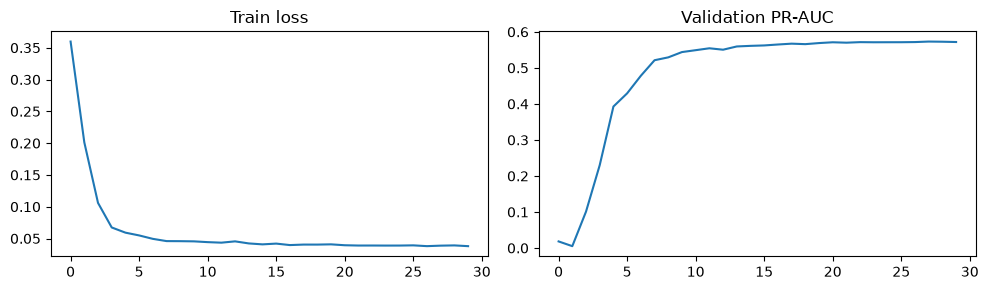

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot([h[0] for h in hist_log]); ax[0].set_title("Train loss"); ax[1].plot([h[1] for h in hist_log]); ax[1].set_title("Validation PR-AUC")
plt.tight_layout(); plt.show()

## 8. Evaluate on the held-out test period
The threshold is chosen on validation (max F1) and applied unchanged to test.

Threshold (from validation): 0.9712

Accuracy     0.9989
Precision    0.7417
Recall       0.6071
F1           0.6677
ROC_AUC      0.9896
PR_AUC       0.5640 

              precision    recall  f1-score   support

       Legit     0.9993    0.9996    0.9995   1013872
  Laundering     0.7417    0.6071    0.6677      1797

    accuracy                         0.9989   1015669
   macro avg     0.8705    0.8034    0.8336   1015669
weighted avg     0.9988    0.9989    0.9989   1015669



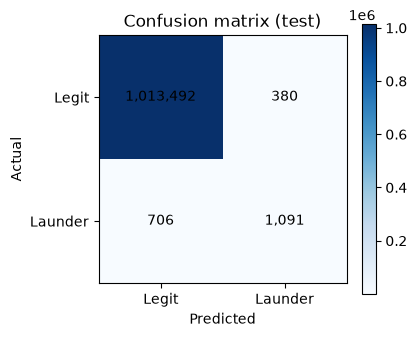

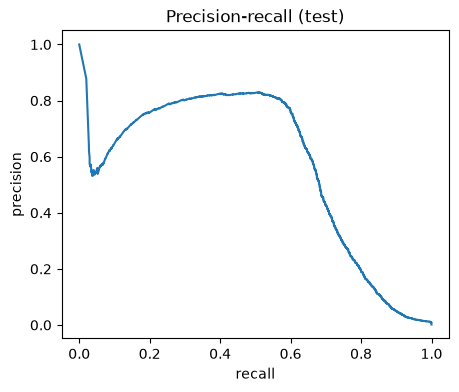

In [13]:
pv, pt = predict(n_tr, n_va), predict(n_va, n)
y_te = Y[n_va:].numpy()
thr = best_threshold(y_va, pv)
results["GNN (edge-aware GINE)"] = report(y_te, pt, thr)
pred = (pt >= thr).astype(int)

print(f"Threshold (from validation): {thr:.4f}\n")
print(pd.Series(results["GNN (edge-aware GINE)"]).round(4).to_string(), "\n")
print(classification_report(y_te, pred, target_names=["Legit","Laundering"], digits=4, zero_division=0))

cm = confusion_matrix(y_te, pred)
plt.figure(figsize=(4, 3.5)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
for i in range(2):
    for j in range(2): plt.text(j, i, f"{cm[i,j]:,}", ha="center", va="center")
plt.xticks([0,1], ["Legit","Launder"]); plt.yticks([0,1], ["Legit","Launder"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (test)"); plt.show()

pr, rc, _ = precision_recall_curve(y_te, pt)
plt.figure(figsize=(5, 4)); plt.plot(rc, pr); plt.xlabel("recall"); plt.ylabel("precision"); plt.title("Precision-recall (test)"); plt.show()

## 9. Retroactive flagging (from the reference notebook)
If an account is involved in a *later* flagged transaction within a look-back window, its earlier transactions that already scored above a minimum level are also flagged. No labels are used; window and minimum score are tuned on validation. **These are delayed alerts** (retrospective tracing, not real-time blocking), so it is reported separately.

In [14]:
def retro(lo, hi, score, thr, window, low):
    s_, r_, secs = SND[lo:hi], RCV[lo:hi], SECS[lo:hi]; flag = score >= thr
    ev = np.sort(np.concatenate([s_[flag]*10**8 + secs[flag], r_[flag]*10**8 + secs[flag]]))
    gap = np.full(hi - lo, np.inf)
    for a in (s_, r_):
        p = np.searchsorted(ev, a*10**8 + secs + 1, side="left"); ok = p < len(ev)
        nxt = np.where(ok, ev[p.clip(max=len(ev)-1)], -1)
        gap = np.minimum(gap, np.where(ok & (nxt // 10**8 == a), nxt - a*10**8 - secs, np.inf))
    return flag | ((gap <= window) & (score >= low))

def prf(y, flag):
    tp = int((flag & (y == 1)).sum()); p, r = tp / max(int(flag.sum()), 1), tp / max(int(y.sum()), 1)
    return dict(Accuracy=(flag == (y == 1)).mean(), Precision=p, Recall=r, F1=2*p*r / max(p+r, 1e-12))

WINDOWS = {"1h": 3600, "6h": 6*3600, "24h": 86400, "3d": 3*86400, "7d": 7*86400}
LOWS = [1.0, 0.95, 0.8, 0.5, 0.2, 0.05, 0.01]
best = max(((prf(y_va, retro(n_tr, n_va, pv, thr, W, lo))["F1"], wn, lo) for wn, W in WINDOWS.items() for lo in LOWS), key=lambda t: t[0])
print(f"chosen on validation: look-back {best[1]}, earlier score >= {best[2]} (val F1 {best[0]:.4f})")
results["GNN + retroactive flagging (delayed)"] = prf(y_te, retro(n_va, n, pt, thr, WINDOWS[best[1]], best[2]))

chosen on validation: look-back 3d, earlier score >= 0.5 (val F1 0.6451)


## 10. Summary (test set)

In [15]:
summary = pd.DataFrame(results).T.round(4)
display(summary)
print("Reference (HI-Small F1): IBM paper GIN 0.287, GIN+edge updates 0.477, PNA 0.568, XGBoost+graph feats 0.632; reference trees notebook ~0.66 (0.71 with retro flagging).")

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Trees (same features),0.9990,0.7976,0.6010,0.6855,0.9840,0.6352
GNN (edge-aware GINE),0.9989,0.7417,0.6071,0.6677,0.9896,0.5640
GNN + retroactive flagging (delayed),0.9990,0.7160,0.6778,0.6964,NaN,NaN


Reference (HI-Small F1): IBM paper GIN 0.287, GIN+edge updates 0.477, PNA 0.568, XGBoost+graph feats 0.632; reference trees notebook ~0.66 (0.71 with retro flagging).


## Notes
- **Accuracy is uninformative** here (≈99.9% of transactions are legitimate); look at F1, precision, recall and PR-AUC of the laundering class.
- **Causality:** the 20 history features use only earlier rows. Splits are chronological. Inside a ~150k-transaction chunk, message passing is not strictly causal (an edge can see later edges of the same chunk), as with the whole-snapshot graphs of the IBM paper. No labels are ever used as inputs.
- **Knobs if you want more F1:** `HIDDEN=128`, `LAYERS=3`, `CHUNK=300_000` (more context, more RAM), `EPOCHS=50`, or a different `pos_weight`.